# T4 — Classificador k-Nearest Neighbour
**Alexsandro Narducci, Cláudio Strohaecker Junior e Lucas Cândido Belletti**

Implementação de 1-NN e k-NN com distância euclidiana. As quatro demonstrações solicitadas estão organizadas em células neste único notebook, entregue em `.ipynb`.

**Execução:** extraia o ZIP, abra este notebook no Jupyter ou no VS Code e execute as células em ordem. Mantenha os quatro arquivos `.mat` na mesma pasta do notebook. No Colab, envie também os quatro `.mat` para a pasta da sessão. Dependências: `numpy`, `scipy` e `matplotlib` (instalação, se necessária: `%pip install numpy scipy matplotlib`). Os resultados e gráficos já estão salvos.

**Cálculos:** distância, votação, normalização min–max e acurácia são implementadas diretamente. SciPy apenas lê os arquivos; NumPy organiza vetores e matrizes; Matplotlib desenha os gráficos. Não usamos um classificador pronto.

A distância é $d(p,q)=\sqrt{\sum_{j=1}^{N}(p_j-q_j)^2}$. Para cada atributo, subtraímos os valores, elevamos ao quadrado, somamos e tiramos a raiz. Cada linha representa um exemplo.

**Critérios de empate:** distâncias iguais preservam a ordem original do treino; votos empatados escolhem o menor rótulo numérico. Isso torna o resultado reproduzível, inclusive para valores pares de k.

**Limite da análise:** os testes de k e atributos usam o conjunto de teste, conforme a exploração solicitada no exercício. Os máximos encontrados são resultados exploratórios dessa divisão, não estimativas independentes de desempenho futuro. Em uma aplicação real, esses ajustes seriam escolhidos com validação no treino, reservando um teste final intocado. Nenhum exemplo ou rótulo é removido ou corrigido para aumentar a acurácia.

In [1]:
# Integrantes: Alexsandro Narducci, Cláudio Strohaecker Junior, Lucas Cândido Belletti
from pathlib import Path
from itertools import combinations
import numpy as np
from scipy.io import loadmat
import matplotlib.pyplot as plt

PASTA_DADOS = Path('.')
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': True,
                     'grid.alpha': 0.2, 'font.size': 10})


def dist(p, q):
    """Calcula a distância euclidiana entre dois vetores de atributos."""
    if len(p) != len(q):
        raise ValueError('Os vetores devem ter o mesmo número de atributos.')
    soma = 0.0
    for j in range(len(p)):
        soma += (float(p[j]) - float(q[j])) ** 2
    return soma ** 0.5


def meuKnn(dadosTrain, rotuloTrain, dadosTeste, k):
    """Classifica cada linha de teste pelo voto dos k vizinhos do treino."""
    treino = np.asarray(dadosTrain, dtype=float)
    teste = np.asarray(dadosTeste, dtype=float)
    rotulos = np.asarray(rotuloTrain).reshape(-1)
    if treino.ndim != 2 or teste.ndim != 2:
        raise ValueError('Treino e teste devem ser matrizes de exemplos por atributos.')
    if treino.shape[1] != teste.shape[1] or treino.shape[1] == 0:
        raise ValueError('Treino e teste devem ter os mesmos atributos, não vazios.')
    if len(treino) != len(rotulos):
        raise ValueError('É necessário um rótulo para cada exemplo de treino.')
    if not isinstance(k, (int, np.integer)) or not 1 <= k <= len(treino):
        raise ValueError('k deve ser inteiro entre 1 e a quantidade de exemplos de treino.')
    if not np.isfinite(treino).all() or not np.isfinite(teste).all():
        raise ValueError('Os atributos devem conter apenas números finitos.')
    previstos = []
    for exemplo in teste:
        distancias = [dist(exemplo, linha) for linha in treino]
        # Ordenação estável: mantém a ordem de treino em distâncias iguais.
        indices = sorted(range(len(treino)), key=lambda i: distancias[i])
        votos = {}
        for indice in indices[:k]:
            rotulo = rotulos[indice]
            votos[rotulo] = votos.get(rotulo, 0) + 1
        # Percorre rótulos em ordem crescente; empate mantém o menor.
        vencedor = None
        maior_contagem = -1
        for rotulo in sorted(votos):
            if votos[rotulo] > maior_contagem:
                vencedor = rotulo
                maior_contagem = votos[rotulo]
        previstos.append(vencedor)
    return np.asarray(previstos, dtype=rotulos.dtype)


def normalizacao(dadosTrain, dadosTeste):
    """Min–max por coluna, calculado SOMENTE no treino e aplicado ao teste."""
    treino = np.asarray(dadosTrain, dtype=float)
    teste = np.asarray(dadosTeste, dtype=float)
    treino_norm = np.empty_like(treino)
    teste_norm = np.empty_like(teste)
    for j in range(treino.shape[1]):
        minimo = min(float(v) for v in treino[:, j])
        maximo = max(float(v) for v in treino[:, j])
        amplitude = maximo - minimo
        if amplitude == 0:
            # Atributo constante no treino não contribui para a distância.
            treino_norm[:, j] = 0.0
            teste_norm[:, j] = 0.0
        else:
            for i in range(len(treino)):
                treino_norm[i, j] = (treino[i, j] - minimo) / amplitude
            for i in range(len(teste)):
                teste_norm[i, j] = (teste[i, j] - minimo) / amplitude
    # Teste pode sair de [0, 1]; não recortamos nem ajustamos sua escala separadamente.
    return treino_norm, teste_norm


def visualizaPontos(dados, rotulos, d1, d2, titulo='Distribuição dos exemplos'):
    """Exibe duas dimensões; d1 e d2 são números de atributos começando em 1."""
    dados = np.asarray(dados)
    rotulos = np.asarray(rotulos).reshape(-1)
    if not 1 <= d1 <= dados.shape[1] or not 1 <= d2 <= dados.shape[1]:
        raise ValueError('Dimensão fora do intervalo de atributos.')
    fig, ax = plt.subplots()
    cores = ['red', 'blue', 'green']
    marcadores = ['^', '+', '.']
    for i, rotulo in enumerate(sorted(set(rotulos))):
        # Equivalente à seleção feita por getDadosRotulo no enunciado.
        x = [linha[d1 - 1] for linha, r in zip(dados, rotulos) if r == rotulo]
        y = [linha[d2 - 1] for linha, r in zip(dados, rotulos) if r == rotulo]
        ax.scatter(x, y, c=cores[i % 3], marker=marcadores[i % 3],
                   label=f'Classe {rotulo}', alpha=0.8)
    ax.set(xlabel=f'Atributo {d1}', ylabel=f'Atributo {d2}', title=titulo)
    ax.legend()
    fig.tight_layout()
    plt.show()


## demoD1 — Flores (Iris)
Conferência dos valores de referência e comparação de atributos. Os índices de colunas no código começam em zero; os números apresentados nas saídas começam em um.

Treino: (100, 4); teste: (50, 4)
Quatro atributos | k= 1: 48/50 = 96.00%
Quatro atributos | k=10: 47/50 = 94.00%
Quatro atributos | k= 3: 49/50 = 98.00%
Melhor com 1 atributo(s): 96.00%; atributos (3,); k=5
Melhor com 2 atributo(s): 98.00%; atributos (1, 3); k=3
Melhor com 3 atributo(s): 98.00%; atributos (1, 3, 4); k=5
Melhor com 4 atributo(s): 98.00%; atributos (1, 2, 3, 4); k=3
Atributos 3 e 4 | k=4: 49/50 = 98.00%


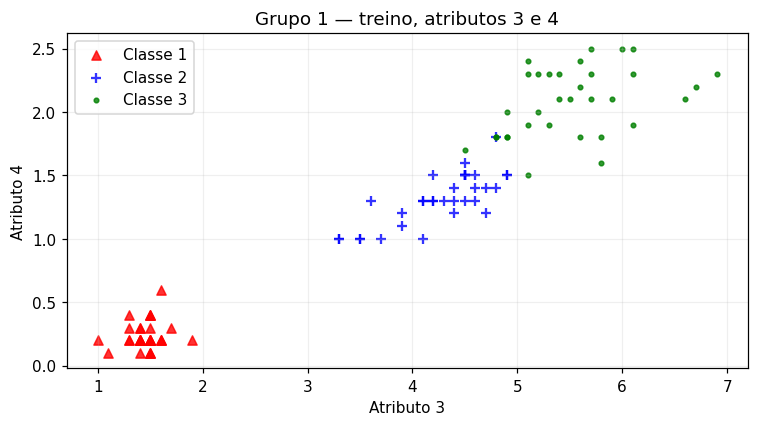

In [2]:
# Integrantes: Alexsandro Narducci, Cláudio Strohaecker Junior, Lucas Cândido Belletti
# Q1.1: 98% (49/50), por exemplo com as quatro características e k=3.
# A busca abaixo considera todos os 15 subconjuntos não vazios e k de 1 a 20,
# sem normalização. "Máxima" refere-se a essa busca, não a qualquer modelo possível.
# Q1.2: Não. Os atributos 3 e 4, com k=4, também alcançam 98%.
# Logo, nesta divisão, dois atributos bastam para igualar o melhor resultado.
mat1 = loadmat(PASTA_DADOS / 'grupoDados1.mat')
x1, y1 = mat1['grupoTrain'], mat1['trainRots'].reshape(-1)
t1, r1 = mat1['grupoTest'], mat1['testRots'].reshape(-1)
print(f'Treino: {x1.shape}; teste: {t1.shape}')
for k in (1, 10, 3):
    previsto = meuKnn(x1, y1, t1, k)
    corretos = sum(int(p == r) for p, r in zip(previsto, r1))
    print(f'Quatro atributos | k={k:2d}: {corretos}/{len(r1)} = {corretos/len(r1):.2%}')

melhor_por_tamanho = {}
for quantidade in range(1, 5):
    melhor = (-1, None, None)
    for colunas in combinations(range(4), quantidade):
        for k in range(1, 21):
            previsto = meuKnn(x1[:, colunas], y1, t1[:, colunas], k)
            corretos = sum(int(p == r) for p, r in zip(previsto, r1))
            if corretos > melhor[0]:
                melhor = (corretos, colunas, k)
    melhor_por_tamanho[quantidade] = melhor
    acertos, colunas, k = melhor
    print(f'Melhor com {quantidade} atributo(s): {acertos/len(r1):.2%}; '
          f'atributos {tuple(c + 1 for c in colunas)}; k={k}')
previsto = meuKnn(x1[:, [2, 3]], y1, t1[:, [2, 3]], 4)
corretos = sum(int(p == r) for p, r in zip(previsto, r1))
print(f'Atributos 3 e 4 | k=4: {corretos}/{len(r1)} = {corretos/len(r1):.2%}')
visualizaPontos(x1, y1, 3, 4, 'Grupo 1 — treino, atributos 3 e 4')


## demoD2 — Composição química dos vinhos
A normalização usa os mínimos e máximos do treino, sem consultar o teste para definir a transformação.

Amplitude dos atributos no treino:
Álcool                    :   11.030 a   14.830
Ácido málico              :    0.740 a    5.650
Cinzas                    :    1.360 a    3.230
Alcalinidade das cinzas   :   10.600 a   30.000
Magnésio                  :   70.000 a  162.000
Fenóis totais             :    0.980 a    3.880
Flavonóides               :    0.340 a    5.080
Fenóis não flavonóides    :    0.130 a    0.630
Proantocianinas           :    0.420 a    3.580
Intensidade de cor        :    1.280 a   13.000
Tonalidade                :    0.480 a    1.710
OD280/OD315               :    1.270 a    4.000
Prolina                   :  278.000 a 1547.000
Original | k=1: 41/60 = 68.33%
Min–max | k=1: 58/60 = 96.67%
Min–max | k=3: 59/60 = 98.33%
Min–max (exploração adicional) | k=9: 60/60 = 100.00%


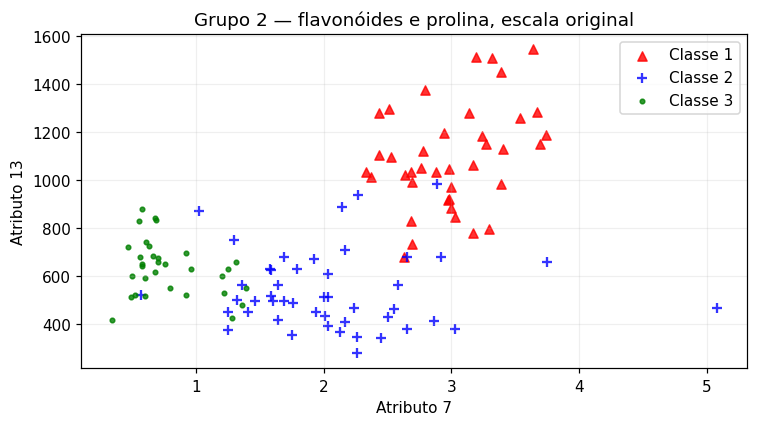

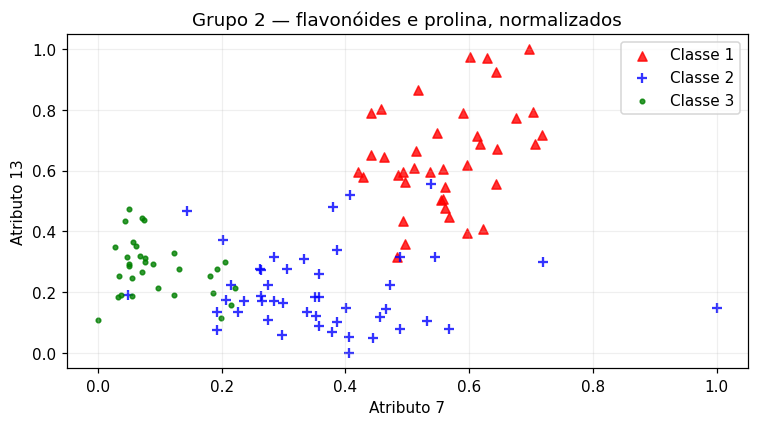

In [3]:
# Integrantes: Alexsandro Narducci, Cláudio Strohaecker Junior, Lucas Cândido Belletti
# Q2.1: Com todos os 13 atributos, sem normalização e k=1, 68,33% (41/60).
# Q2.2: Min–max e k=3 elevam o resultado para 98,33% (59/60), aproximadamente 98%.
# A prolina varia de 278 a 1547 no treino, enquanto a tonalidade varia de 0,48
# a 1,71. Sem normalização, atributos de grande escala dominam a soma dos
# quadrados, embora isso não signifique maior relevância para a classificação.
# Min–max equilibra as amplitudes; k=3 usa votação para reduzir decisões isoladas.
# Não existe exatamente 98% com 60 testes: cada acerto representa 1,6667 ponto.
mat2 = loadmat(PASTA_DADOS / 'grupoDados2.mat')
x2, y2 = mat2['grupoTrain'], mat2['trainRots'].reshape(-1)
t2, r2 = mat2['grupoTest'], mat2['testRots'].reshape(-1)
x2n, t2n = normalizacao(x2, t2)
nomes_atributos = ['Álcool', 'Ácido málico', 'Cinzas', 'Alcalinidade das cinzas',
                  'Magnésio', 'Fenóis totais', 'Flavonóides', 'Fenóis não flavonóides',
                  'Proantocianinas', 'Intensidade de cor', 'Tonalidade',
                  'OD280/OD315', 'Prolina']
print('Amplitude dos atributos no treino:')
for j, nome in enumerate(nomes_atributos):
    print(f'{nome:26s}: {min(x2[:, j]):8.3f} a {max(x2[:, j]):8.3f}')
for descricao, treino, teste, k in [
    ('Original', x2, t2, 1), ('Min–max', x2n, t2n, 1),
    ('Min–max', x2n, t2n, 3), ('Min–max (exploração adicional)', x2n, t2n, 9)]:
    previsto = meuKnn(treino, y2, teste, k)
    corretos = sum(int(p == r) for p, r in zip(previsto, r2))
    print(f'{descricao} | k={k}: {corretos}/{len(r2)} = {corretos/len(r2):.2%}')
# A meta não é um teto: nesta divisão, min–max com k=9 também alcança 100%.
visualizaPontos(x2, y2, 7, 13, 'Grupo 2 — flavonóides e prolina, escala original')
visualizaPontos(x2n, y2, 7, 13, 'Grupo 2 — flavonóides e prolina, normalizados')


## demoD3 — Sensibilidade a rótulos ruidosos
A comparação com o grupo 1 é usada apenas para diagnosticar a alteração dos dados. A classificação mantém os rótulos fornecidos no grupo 3.

Treino coincide com atributos 1 e 4 do grupo 1: True
Teste coincide com atributos 1 e 4 do grupo 1: True
Rótulos de teste preservados: True
Rótulos de treino diferentes: 33
k= 1: 35/50 = 70.00%
k= 7: 46/50 = 92.00%
k=10: 48/50 = 96.00%


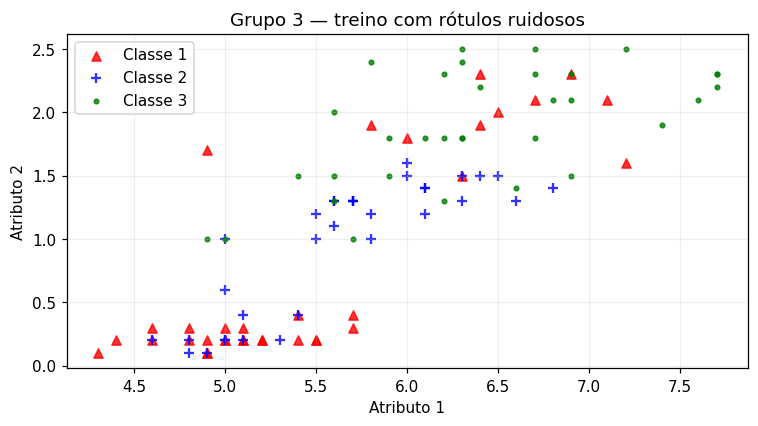

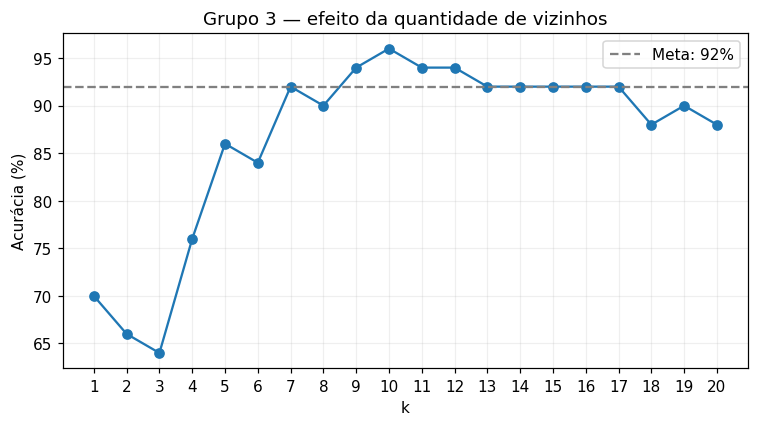

In [4]:
# Integrantes: Alexsandro Narducci, Cláudio Strohaecker Junior, Lucas Cândido Belletti
# Q3.1: k=1 obtém 70% (35/50).
# Q3.2: Mantendo os dados e aumentando k para 7, obtemos 92% (46/50).
# O grupo 3 reutiliza os atributos 1 e 4 do grupo 1, mas tem 33 rótulos de
# treino diferentes. São exemplos que podem contrariar os vizinhos da região.
# 1-NN depende de um único rótulo; k=7 ameniza o ruído por votação local.
# Não corrigimos os rótulos com o grupo 1 nem removemos exemplos.
# Outliers de atributos e rótulos alterados são problemas distintos; aqui a
# comparação permite verificar diretamente o ruído nos rótulos.
mat3 = loadmat(PASTA_DADOS / 'grupoDados3.mat')
x3, y3 = mat3['grupoTrain'], mat3['trainRots'].reshape(-1)
t3, r3 = mat3['grupoTest'], mat3['testRots'].reshape(-1)
print('Treino coincide com atributos 1 e 4 do grupo 1:',
      np.array_equal(x3, x1[:, [0, 3]]))
print('Teste coincide com atributos 1 e 4 do grupo 1:',
      np.array_equal(t3, t1[:, [0, 3]]))
print('Rótulos de teste preservados:', np.array_equal(r3, r1))
print('Rótulos de treino diferentes:', sum(int(a != b) for a, b in zip(y3, y1)))
ks = list(range(1, 21))
acuracias3 = []
for k in ks:
    previsto = meuKnn(x3, y3, t3, k)
    corretos = sum(int(p == r) for p, r in zip(previsto, r3))
    acuracias3.append(corretos / len(r3))
    if k in (1, 7, 10):
        print(f'k={k:2d}: {corretos}/{len(r3)} = {corretos/len(r3):.2%}')
# k=10 chega a 96% nesta exploração: a meta de 92% não é o máximo possível.
visualizaPontos(x3, y3, 1, 2, 'Grupo 3 — treino com rótulos ruidosos')
fig, ax = plt.subplots()
ax.plot(ks, [100 * a for a in acuracias3], marker='o')
ax.axhline(92, color='gray', linestyle='--', label='Meta: 92%')
ax.set(xlabel='k', ylabel='Acurácia (%)', title='Grupo 3 — efeito da quantidade de vizinhos', xticks=ks)
ax.legend()
fig.tight_layout()
plt.show()


## demoD4 — Escalas e atributos pouco informativos
Comparamos o efeito de cada ajuste separadamente antes de combiná-los.

Duas primeiras colunas correspondem ao grupo 2 (treino e teste): True
Quatro atributos originais     | k=1: 43/60 = 71.67%
Quatro atributos normalizados  | k=1: 47/60 = 78.33%
Atributos 1 e 2 originais      | k=1: 43/60 = 71.67%
Atributos 1 e 2 normalizados   | k=1: 56/60 = 93.33%
Atributos 1 e 2 normalizados   | k=3: 55/60 = 91.67%


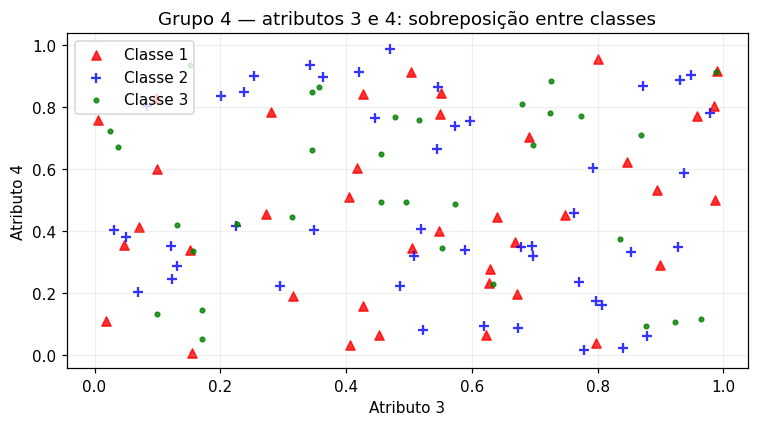

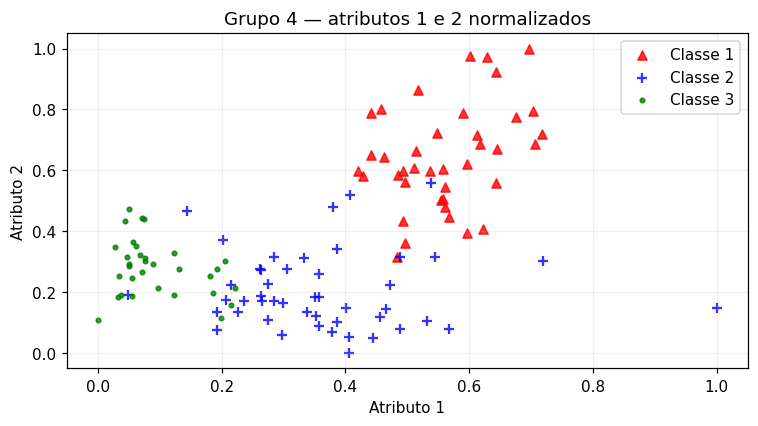

In [5]:
# Integrantes: Alexsandro Narducci, Cláudio Strohaecker Junior, Lucas Cândido Belletti
# Q4.1: Com os quatro atributos originais e k=1, 71,67% (43/60).
# Q4.2: Selecionar os atributos 1 e 2, normalizar por min–max e usar k=3
# resulta em 91,67% (55/60), que arredondado é 92%.
# Problema 1: o atributo 2 tem uma amplitude muito maior e domina a distância.
# Problema 2: os atributos 3 e 4 prejudicam a vizinhança; seus gráficos mostram
# sobreposição entre classes. Os resultados são compatíveis com atributos
# ruidosos/pouco informativos, mas não provam como eles foram gerados.
# As duas primeiras colunas coincidem com flavonóides e prolina do grupo 2.
# Normalizar as quatro colunas também dá peso às colunas pouco informativas;
# por isso combinamos seleção de atributos e normalização.
# Com os mesmos dois atributos normalizados e k=1, chega-se a 93,33% (56/60).
# Portanto, 92% é a referência arredondada do enunciado, não um teto.
mat4 = loadmat(PASTA_DADOS / 'grupoDados4.mat')
x4, y4 = mat4['trainSet'], mat4['trainLabs'].reshape(-1)
t4, r4 = mat4['testSet'], mat4['testLabs'].reshape(-1)
print('Duas primeiras colunas correspondem ao grupo 2 (treino e teste):',
      np.array_equal(x4[:, :2], x2[:, [6, 12]]) and
      np.array_equal(t4[:, :2], t2[:, [6, 12]]))
x4n, t4n = normalizacao(x4, t4)
x4s, t4s = x4[:, :2], t4[:, :2]
x4sn, t4sn = normalizacao(x4s, t4s)
for descricao, treino, teste, k in [
    ('Quatro atributos originais', x4, t4, 1),
    ('Quatro atributos normalizados', x4n, t4n, 1),
    ('Atributos 1 e 2 originais', x4s, t4s, 1),
    ('Atributos 1 e 2 normalizados', x4sn, t4sn, 1),
    ('Atributos 1 e 2 normalizados', x4sn, t4sn, 3)]:
    previsto = meuKnn(treino, y4, teste, k)
    corretos = sum(int(p == r) for p, r in zip(previsto, r4))
    print(f'{descricao:30s} | k={k}: {corretos}/{len(r4)} = {corretos/len(r4):.2%}')
visualizaPontos(x4, y4, 3, 4, 'Grupo 4 — atributos 3 e 4: sobreposição entre classes')
visualizaPontos(x4sn, y4, 1, 2, 'Grupo 4 — atributos 1 e 2 normalizados')


## Respostas resumidas

| Questão | Resultado observado | Configuração |
|---|---|---|
| Q1.1 | 98% (49/50), melhor na busca descrita | Quatro atributos, k=3, sem normalização |
| Q1.2 | Não são necessários todos os atributos | Atributos 3 e 4, k=4: 98% |
| Q2.1 | 68,33% (41/60) | Original, k=1 |
| Q2.2 | 98,33% (59/60), aproximadamente 98% | Min–max, k=3 |
| Q3.1 | 70% (35/50) | Original, k=1 |
| Q3.2 | 92% (46/50) | Mesmos dados, k=7 |
| Q4.1 | 71,67% (43/60) | Original, k=1 |
| Q4.2 | 91,67% (55/60), aproximadamente 92% | Atributos 1 e 2, min–max, k=3 |

Os resultados dependem da divisão fornecida e da regra de desempate documentada. Todas as acurácias usam os rótulos reais de teste apenas na avaliação, nunca como entrada do classificador.